# Transfer through feature-distribution alignment

A separate, fixed follow-up to the source-leaf experiment tests a different mechanism: the cities have different spectral/temporal feature means and scales. Estimate target moments from **only the permitted labeled adaptation locations**, map them into source units, then apply the frozen Madrid forest.

Two procedures are fixed before the outer experiment: **full moment alignment** and **shrunk moment alignment** with a fixed prior count of 40. Both average the aligned source and target forest probabilities 50/50. No outer score chooses between variants. Class-balanced source reference statistics reflect the equal-per-class allocation of the target sample. Neither target reference statistics nor model parameters use evaluation locations.

This remains iterative development: prior baseline and early leaf-adapter results motivated this experiment. These development comparisons are not an independent final test. All five budgets, five spatial folds and three sampling repetitions are kept.

Skills: [scikit-learn](docs/upstream-skills/scikit-learn/SKILL.md) preprocessing/pipelines/evaluation and [verification-before-completion](docs/upstream-skills/verification-before-completion/SKILL.md). Implementations are in `scripts/moment_transfer.py` and shared helpers in `scripts/transfer_adaptation.py`.


In [ ]:
from scripts.transfer_adaptation import target_forest, probabilities, CLASSES
from scripts.moment_transfer import fit_source_reference, fit_target_moments, aligned_source_probabilities
from pathlib import Path
import sys
import json
import hashlib
import time
import gc
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'pyproject.toml').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
BASELINE = ROOT/'data'/'baseline'
INPUT = ROOT/'data'/'preprocessed_age_labels'
OUTPUT = ROOT/'data'/'transfer_alignment'
OUTPUT.mkdir(parents=True, exist_ok=True)
CONFIG = json.loads((BASELINE/'experiment.json').read_text())
FEATURES = CONFIG['feature_names']
RF_PARAMS = CONFIG['rf_parameters']
SEED = CONFIG['seed']
BUDGETS = CONFIG['preprocessing_configuration']['budgets']
N_FOLDS = CONFIG['preprocessing_configuration']['n_folds']
REPETITIONS = CONFIG['repetitions']
VARIANTS = {'full_moment_alignment': 0., 'shrunk_moment_alignment': 40.}


def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''): h.update(block)
    return h.hexdigest()


manifest = json.loads((BASELINE/'manifest.json').read_text())
for name in ['madrid_source_model.joblib', 'adaptation_membership.csv', 'validation_predictions.parquet', 'fold_metrics.csv', 'summary.csv']:
    assert sha256(BASELINE/name) == manifest[name]['sha256']
for name in ['madrid_supervised_features.parquet', 'amsterdam_supervised_features.parquet']:
    assert sha256(INPUT/name) == CONFIG['input_hashes'][name]
SOURCE_HASH = sha256(BASELINE/'madrid_source_model.joblib')
SOURCE = joblib.load(BASELINE/'madrid_source_model.joblib')
MADRID = pd.read_parquet(INPUT/'madrid_supervised_features.parquet')
AMSTERDAM = pd.read_parquet(INPUT/'amsterdam_supervised_features.parquet')
MEMBERSHIP = pd.read_csv(BASELINE/'adaptation_membership.csv')
OLD_METRICS = pd.read_csv(BASELINE/'fold_metrics.csv')
OLD_SUMMARY = pd.read_csv(BASELINE/'summary.csv')
OLD_PREDICTIONS = pd.read_parquet(BASELINE/'validation_predictions.parquet')
REFERENCE = fit_source_reference(SOURCE, MADRID[FEATURES], MADRID.age_class)
POSITIONS = pd.Series(np.arange(len(AMSTERDAM)), index=AMSTERDAM.location_id)
print('Frozen source reference uses',
      REFERENCE['n_source'], 'Madrid locations. Target evaluation locations never enter moment fits.')

Frozen source reference uses 76263 Madrid locations. Target evaluation locations never enter moment fits.


## Fixed transformation and limitations

For each feature, map `x` to `(x − target_mean) * source_std/target_std + source_mean`. A fixed variance floor prevents excessive expansion of almost-constant features. The shrunk variant combines target moments with the source reference using `n/(n+40)`; it is a prespecified sensitivity comparison, not a parameter selected from outer results.

Per-feature alignment does not align the full covariance or guarantee class-conditional alignment. Different materials, spatial contexts and label boundaries may remain. The target forest still learns directly from raw target features and keeps its own training-only imputer. This notebook changes the source branch, not the target label budget or baseline hyperparameters.


In [2]:
metrics = []
classes = []
confusions = []
parts = []
old = OLD_PREDICTIONS.loc[OLD_PREDICTIONS.city.eq(
    'Amsterdam') & OLD_PREDICTIONS.strategy.eq('source_target_blend')]
SOURCE_RAW_PROB = probabilities(SOURCE, AMSTERDAM[FEATURES])
for fold in range(N_FOLDS):
    evaluation = AMSTERDAM.loc[AMSTERDAM.fold.eq(fold)]
    eval_positions = POSITIONS.loc[evaluation.location_id].to_numpy()
    for repetition in range(REPETITIONS):
        for n in BUDGETS:
            ids = MEMBERSHIP.loc[MEMBERSHIP.fold.eq(fold) & MEMBERSHIP.repetition.eq(
                repetition) & MEMBERSHIP.samples_per_class.eq(n), 'location_id']
            sample = AMSTERDAM.iloc[POSITIONS.loc[ids].to_numpy()]
            assert sample.location_id.is_unique and len(sample) == 4*n
            assert sample.age_class.value_counts().reindex(CLASSES).eq(n).all()
            assert set(sample.location_id).isdisjoint(evaluation.location_id)
            assert set(sample.spatial_group).isdisjoint(
                evaluation.spatial_group)
            target_moments = fit_target_moments(SOURCE, sample[FEATURES])
            target = target_forest(SEED+10_000+100*fold+repetition, RF_PARAMS)
            target.fit(sample[FEATURES], sample.age_class)
            target_prob = probabilities(target, evaluation[FEATURES])
            baseline_pred = CLASSES[(.5*SOURCE_RAW_PROB[eval_positions]+.5 *
                                     target_prob).argmax(axis=1)]
            previous = old.loc[old.fold.eq(fold) & old.repetition.eq(repetition) & old.samples_per_class.eq(
                n)].set_index('location_id').loc[evaluation.location_id]
            np.testing.assert_array_equal(
                baseline_pred, previous.y_pred.to_numpy())
            for variant, prior in VARIANTS.items():
                aligned_prob = aligned_source_probabilities(
                    SOURCE, evaluation[FEATURES], REFERENCE, target_moments, prior)
                prediction = CLASSES[(.5*aligned_prob+.5 *
                                      target_prob).argmax(axis=1)]
                meta = {'strategy': variant, 'fold': fold,
                        'samples_per_class': n, 'repetition': repetition}
                y = evaluation.age_class.to_numpy(dtype=int)
                score = f1_score(y, prediction, labels=CLASSES,
                                 average='macro', zero_division=0)
                metrics.append(
                    {**meta, 'macro_f1': score, 'n_validation': len(y)})
                p, r, f, s = precision_recall_fscore_support(
                    y, prediction, labels=CLASSES, zero_division=0)
                for i, c in enumerate(CLASSES):
                    classes.append(
                        {**meta, 'age_class': int(c), 'precision': p[i], 'recall': r[i], 'f1': f[i], 'support': int(s[i])})
                matrix = confusion_matrix(y, prediction, labels=CLASSES)
                for i, a in enumerate(CLASSES):
                    for j, b in enumerate(CLASSES):
                        confusions.append({**meta, 'true_class': int(a), 'predicted_class': int(
                            b), 'count': int(matrix[i, j]), 'row_proportion': matrix[i, j]/matrix[i].sum()})
                part = evaluation[['location_id', 'age_class']].rename(
                    columns={'age_class': 'y_true'}).copy()
                part['y_pred'] = prediction
                for key, value in meta.items():
                    part[key] = value
                parts.append(part)
                if fold == 0 and repetition == 0:
                    bundle = {'target_pipeline': target, 'source_reference': REFERENCE, 'target_moments': target_moments,
                              'prior_count': prior, 'features': FEATURES, 'source_model_file': '../baseline/madrid_source_model.joblib',
                              'source_sha256': SOURCE_HASH, 'adaptation_location_ids': sample.location_id.tolist(),
                              'excluded_Amsterdam_fold': fold, 'samples_per_class': n, 'variant': variant}
                    joblib.dump(bundle, OUTPUT /
                                f'{variant}_fold0_n{n}.joblib', compress=3)
            print(
                f'Fold {fold}, rep {repetition}, {n}/class: full={metrics[-2]["macro_f1"]:.4f}, shrunk={metrics[-1]["macro_f1"]:.4f}', flush=True)
    gc.collect()

Fold 0, rep 0, 5/class: full=0.4225, shrunk=0.4461
Fold 0, rep 0, 25/class: full=0.5384, shrunk=0.5350
Fold 0, rep 0, 50/class: full=0.5830, shrunk=0.5860
Fold 0, rep 0, 100/class: full=0.5947, shrunk=0.5955
Fold 0, rep 0, 200/class: full=0.6034, shrunk=0.6029
Fold 0, rep 1, 5/class: full=0.4590, shrunk=0.4796
Fold 0, rep 1, 25/class: full=0.5288, shrunk=0.5411
Fold 0, rep 1, 50/class: full=0.5636, shrunk=0.5692
Fold 0, rep 1, 100/class: full=0.5735, shrunk=0.5774
Fold 0, rep 1, 200/class: full=0.5887, shrunk=0.5891
Fold 0, rep 2, 5/class: full=0.4531, shrunk=0.4915
Fold 0, rep 2, 25/class: full=0.5247, shrunk=0.5271
Fold 0, rep 2, 50/class: full=0.5537, shrunk=0.5576
Fold 0, rep 2, 100/class: full=0.5784, shrunk=0.5782
Fold 0, rep 2, 200/class: full=0.6069, shrunk=0.6019
Fold 1, rep 0, 5/class: full=0.4661, shrunk=0.5183
Fold 1, rep 0, 25/class: full=0.5312, shrunk=0.5400
Fold 1, rep 0, 50/class: full=0.5674, shrunk=0.5770
Fold 1, rep 0, 100/class: full=0.6107, shrunk=0.6171
Fold 1, r

## Paired budget results

Report every tested variant. Average three repetitions within each fold first, then compute mean and sample SD across five folds. The paired change uses the original fixed blend on exactly the same folds and label samples. No significance or independent-test claim is made.


,strategy,samples_per_class,macro_f1_mean,macro_f1_fold_sd,delta_f1_mean,delta_f1_fold_sd
0,full_moment_alignment,5,0.4580,0.0217,-0.0158,0.0118
1,full_moment_alignment,25,0.5437,0.0242,-0.0057,0.0080
2,full_moment_alignment,50,0.5837,0.0213,-0.0050,0.0065
3,full_moment_alignment,100,0.6107,0.0241,-0.0060,0.0039
4,full_moment_alignment,200,0.6283,0.0185,-0.0038,0.0067
5,shrunk_moment_alignment,5,0.4824,0.0212,0.0087,0.0092
6,shrunk_moment_alignment,25,0.5519,0.0242,0.0025,0.0040
7,shrunk_moment_alignment,50,0.5906,0.0232,0.0019,0.0066
8,shrunk_moment_alignment,100,0.6132,0.0231,-0.0035,0.0036
9,shrunk_moment_alignment,200,0.6295,0.0199,-0.0026,0.0054


,strategy,samples_per_class,age_class,precision,recall,f1
4,full_moment_alignment,25,1,0.7245,0.5629,0.6307
5,full_moment_alignment,25,2,0.5414,0.5877,0.5616
6,full_moment_alignment,25,3,0.5445,0.4505,0.4892
7,full_moment_alignment,25,4,0.4019,0.6526,0.4932
24,shrunk_moment_alignment,25,1,0.7206,0.5714,0.6353
25,shrunk_moment_alignment,25,2,0.5404,0.6151,0.5737
26,shrunk_moment_alignment,25,3,0.5602,0.4541,0.4977
27,shrunk_moment_alignment,25,4,0.4263,0.6224,0.5008


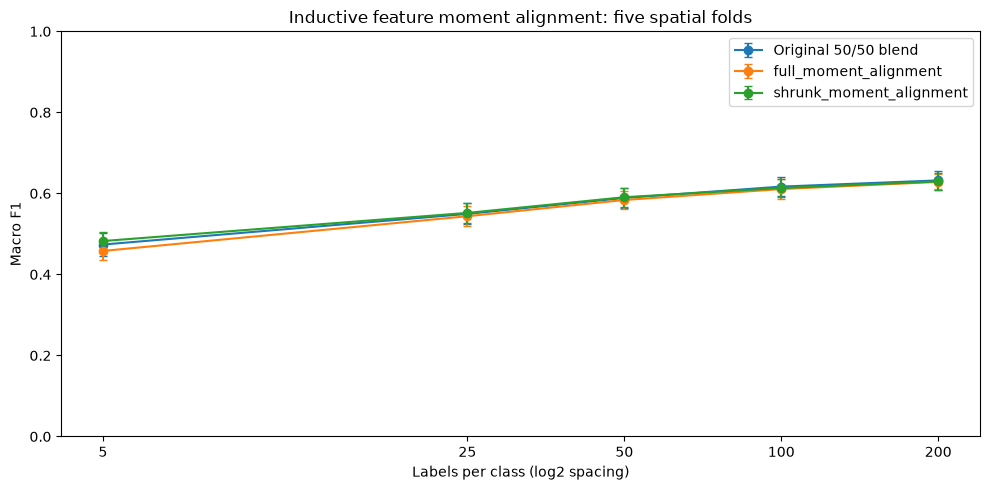

In [3]:
METRICS = pd.DataFrame(metrics)
CLASS_METRICS = pd.DataFrame(classes)
CONFUSIONS = pd.DataFrame(confusions)
PREDICTIONS = pd.concat(parts, ignore_index=True)
FOLD = METRICS.groupby(['strategy', 'samples_per_class',
                       'fold'], as_index=False).macro_f1.mean()
SUMMARY = FOLD.groupby(['strategy', 'samples_per_class'], as_index=False).agg(
    macro_f1_mean=('macro_f1', 'mean'), macro_f1_fold_sd=('macro_f1', 'std'))
old_fold = OLD_METRICS.loc[OLD_METRICS.strategy.eq('source_target_blend')].groupby(
    ['samples_per_class', 'fold'], as_index=False).macro_f1.mean().rename(columns={'macro_f1': 'baseline_f1'})
PAIRED = FOLD.merge(
    old_fold, on=['samples_per_class', 'fold'], validate='many_to_one')
PAIRED['delta_f1'] = PAIRED.macro_f1-PAIRED.baseline_f1
DELTA = PAIRED.groupby(['strategy', 'samples_per_class'], as_index=False).agg(
    delta_f1_mean=('delta_f1', 'mean'), delta_f1_fold_sd=('delta_f1', 'std'))
COMPARISON = SUMMARY.merge(
    DELTA, on=['strategy', 'samples_per_class'], validate='one_to_one')
CLASS_SUMMARY = CLASS_METRICS.groupby(['strategy', 'samples_per_class', 'age_class'], as_index=False)[
    ['precision', 'recall', 'f1']].mean()
display(COMPARISON.round(4))
display(CLASS_SUMMARY.loc[CLASS_SUMMARY.samples_per_class.eq(25)].round(4))
fig, ax = plt.subplots(figsize=(10, 5))
b = OLD_SUMMARY.loc[OLD_SUMMARY.strategy.eq(
    'source_target_blend')].sort_values('samples_per_class')
ax.errorbar(np.log2(b.samples_per_class), b.macro_f1_mean,
            yerr=b.macro_f1_fold_sd, marker='o', capsize=3, label='Original 50/50 blend')
for variant in VARIANTS:
    s = SUMMARY.loc[SUMMARY.strategy.eq(
        variant)].sort_values('samples_per_class')
    ax.errorbar(np.log2(s.samples_per_class), s.macro_f1_mean,
                yerr=s.macro_f1_fold_sd, marker='o', capsize=3, label=variant)
ax.set_xticks(np.log2(BUDGETS), [str(n) for n in BUDGETS])
ax.set(xlabel='Labels per class (log2 spacing)', ylabel='Macro F1', ylim=(
    0, 1), title='Inductive feature moment alignment: five spatial folds')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT/'alignment_learning_curve.png', bbox_inches='tight')
plt.show()

## Verification, persistence and experiment record

Verify every recorded F1 from predictions, reconstruct the baseline, and reload all ten stored adapters. The source model hash must remain unchanged. Store full fold/class metrics and validation predictions, not just a favorable headline.

The procedure can be applied to a new city from a source model and a budget-limited sample alone. These saved examples exclude fold 0 and must not be described as fitted on evaluation labels. Changing the prior count or source reference after looking at outer results would be a new development experiment.


In [4]:
RUN = ['strategy', 'samples_per_class', 'fold', 'repetition']
assert len(METRICS) == len(VARIANTS)*N_FOLDS*REPETITIONS*len(BUDGETS)
assert not PREDICTIONS.duplicated(RUN+['location_id']).any()
for key, group in PREDICTIONS.groupby(RUN):
    selected = METRICS
    for column, value in zip(RUN, key):
        selected = selected.loc[selected[column].eq(value)]
    assert len(selected) == 1
    assert np.isclose(selected.macro_f1.iloc[0], f1_score(
        group.y_true, group.y_pred, labels=CLASSES, average='macro', zero_division=0))
for variant in VARIANTS:
    for n in BUDGETS:
        bundle = joblib.load(OUTPUT/f'{variant}_fold0_n{n}.joblib')
        evaluation = AMSTERDAM.loc[AMSTERDAM.fold.eq(0)]
        assert set(bundle['adaptation_location_ids']
                   ).isdisjoint(evaluation.location_id)
        p = aligned_source_probabilities(
            SOURCE, evaluation[FEATURES], bundle['source_reference'], bundle['target_moments'], bundle['prior_count'])
        q = probabilities(bundle['target_pipeline'], evaluation[FEATURES])
        predicted = CLASSES[(.5*p+.5*q).argmax(axis=1)]
        expected = PREDICTIONS.loc[PREDICTIONS.strategy.eq(variant) & PREDICTIONS.fold.eq(0) & PREDICTIONS.repetition.eq(
            0) & PREDICTIONS.samples_per_class.eq(n)].set_index('location_id').loc[evaluation.location_id, 'y_pred']
        np.testing.assert_array_equal(predicted, expected.to_numpy())
assert sha256(BASELINE/'madrid_source_model.joblib') == SOURCE_HASH
for name, frame in [('fold_metrics', METRICS), ('summary', SUMMARY), ('comparison', COMPARISON), ('paired_fold_differences', PAIRED), ('class_metrics', CLASS_METRICS), ('class_summary', CLASS_SUMMARY), ('confusion_matrices', CONFUSIONS)]:
    frame.to_csv(OUTPUT/f'{name}.csv', index=False)
PREDICTIONS.to_parquet(OUTPUT/'validation_predictions.parquet', index=False)
provenance = {'variants': VARIANTS, 'source_reference_class_balanced': True, 'source_hash': SOURCE_HASH, 'features': FEATURES,
              'target_statistics_fit_only_on_budget_sample': True, 'organizer_test_sets_used': False, 'outer_results_previously_viewed': True,
              'baseline_config': CONFIG, 'helper_sha256': sha256(ROOT/'scripts'/'moment_transfer.py'),
              'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit_learn': sklearn.__version__}}
(OUTPUT/'experiment.json').write_text(json.dumps(provenance, indent=2)+'\n')
lines = ['# Inductive feature-alignment transfer results', '',
         'Two fixed procedures align target feature means and scales toward a class-balanced Madrid reference, using only the budget-limited adaptation sample. Both combine aligned-source and target-forest probabilities with fixed equal weights.', '',
         '| Labels/class | Original blend | Full alignment | Δ F1 | Shrunk alignment | Δ F1 |', '| ---: | ---: | ---: | ---: | ---: | ---: |']
for n in BUDGETS:
    old = OLD_SUMMARY.loc[OLD_SUMMARY.strategy.eq(
        'source_target_blend') & OLD_SUMMARY.samples_per_class.eq(n)].iloc[0]
    a = COMPARISON.loc[COMPARISON.strategy.eq(
        'full_moment_alignment') & COMPARISON.samples_per_class.eq(n)].iloc[0]
    b = COMPARISON.loc[COMPARISON.strategy.eq(
        'shrunk_moment_alignment') & COMPARISON.samples_per_class.eq(n)].iloc[0]
    lines.append(f'| {n} | {old.macro_f1_mean:.4f} ± {old.macro_f1_fold_sd:.4f} | {a.macro_f1_mean:.4f} ± {a.macro_f1_fold_sd:.4f} | {a.delta_f1_mean:+.4f} | {b.macro_f1_mean:.4f} ± {b.macro_f1_fold_sd:.4f} | {b.delta_f1_mean:+.4f} |')
lines += ['', 'Five outer spatial folds and three matched label-sampling repetitions; repetitions average within a fold before mean/SD. SD is descriptive, not a confidence interval. All samples and target-forest seeds match baseline, verified by reconstructing every old prediction.', '',
          'All source reference statistics use Madrid training data. Target statistics, imputation and target trees fit only the allocated Amsterdam labels; evaluation locations/blocks are excluded. No added local labels or runtime dependencies. Prior count 40 and variance floor 0.01 are fixed design choices, not selected from outer scores.', '',
          'This follow-up was motivated by baseline distribution shift and early source-leaf results. These are iterative development results; no variant is declared an unbiased winner based on this comparison. Confirm gains on untouched organizer data. Label-boundary and touching-block limitations remain.', '',
          'Run `transfer_alignment.ipynb` after preprocessing and baseline. Helpers are in `scripts/moment_transfer.py`; artifacts and exact settings are in `data/transfer_alignment/`. Ten saved demonstration adapters exclude Amsterdam fold 0. The separate leaf-selection experiment is retained in `transfer_improved.ipynb` and `docs/TRANSFER_RESULTS.md`.', '',
          'Skills: downloaded scikit-learn and verification-before-completion instructions in `docs/upstream-skills/`. Citation: Kassis et al. (2026), *Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents*, https://doi.org/10.48550/arXiv.2609.00065.']
(ROOT/'docs'/'TRANSFER_ALIGNMENT_RESULTS.md').write_text('\n'.join(lines)+'\n')
pd.testing.assert_frame_equal(PREDICTIONS, pd.read_parquet(
    OUTPUT/'validation_predictions.parquet'))
manifest = {p.name: {'bytes': p.stat().st_size, 'sha256': sha256(p)} for p in sorted(
    OUTPUT.iterdir()) if p.is_file() and p.name != 'manifest.json'}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest, indent=2)+'\n')
print('All prediction, budget, exclusion, model-reload and export checks passed.')
print('Report:', ROOT/'docs'/'TRANSFER_ALIGNMENT_RESULTS.md')

All prediction, budget, exclusion, model-reload and export checks passed.
Report: /home/mirado/hack4dev/Building_Age_Classification/docs/TRANSFER_ALIGNMENT_RESULTS.md
